C:\Users\priya\AppData\Local\Temp\ipykernel_22792\3856512445.py:96: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(images[i].flatten(), 256, [0,256], color='blue', alpha=0.7)


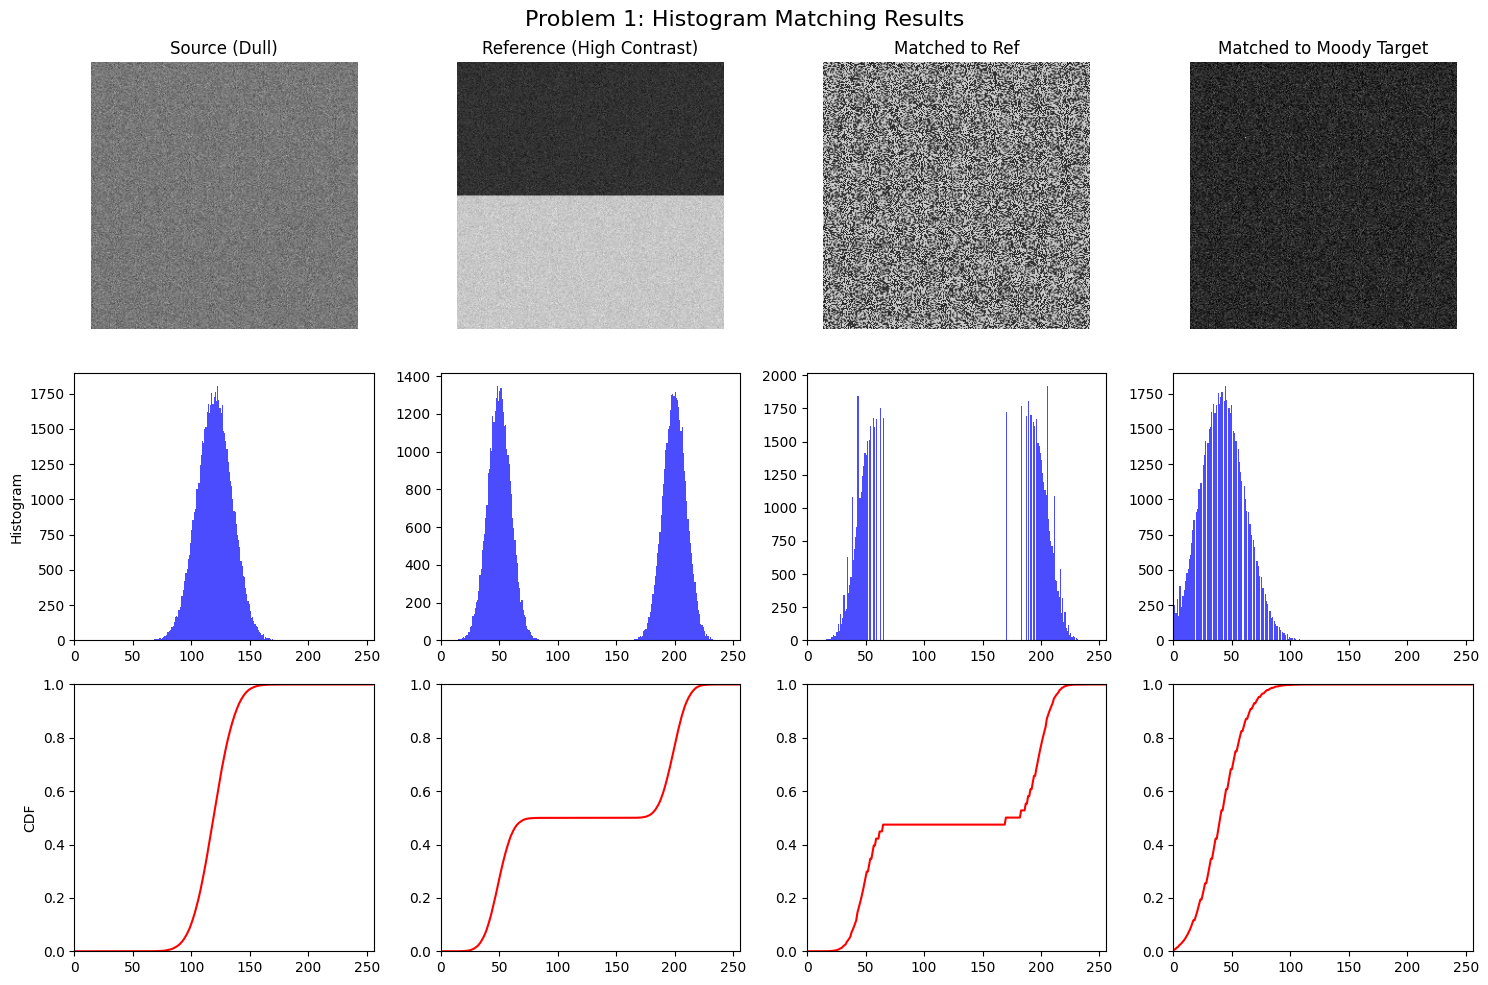

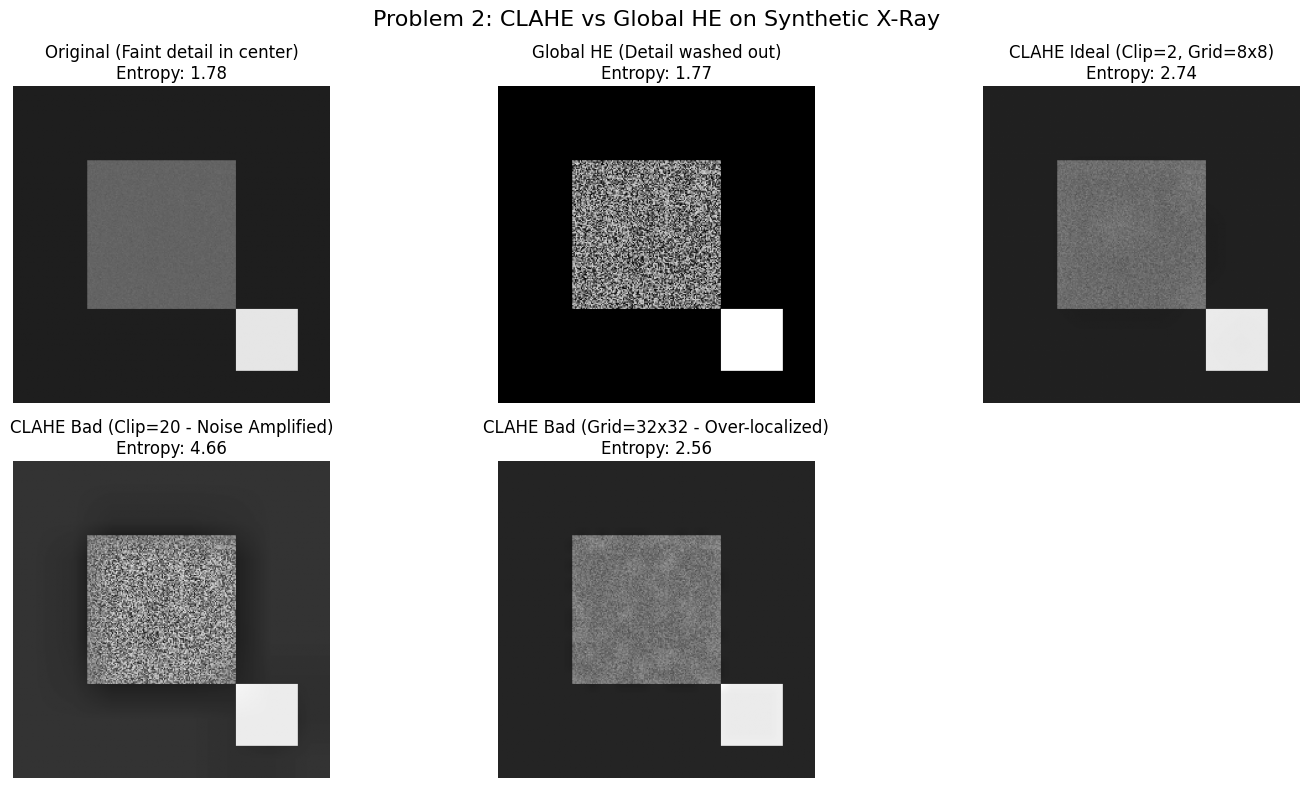

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
import scipy.stats as stats

# ==========================================
# 1. FUNCTION DEFINITIONS
# ==========================================

def get_cdf(image):
    """Calculates the normalized CDF of an image."""
    hist, _ = np.histogram(image.flatten(), 256, [0,256])
    cdf = hist.cumsum()
    cdf_normalized = cdf / float(cdf.max())
    return cdf_normalized

def match_histograms(source, reference):
    """Maps source image to reference histogram from first principles."""
    src_cdf = get_cdf(source)
    ref_cdf = get_cdf(reference)
    
    lookup_table = np.zeros(256)
    for src_pixel_val in range(256):
        diff = np.abs(ref_cdf - src_cdf[src_pixel_val])
        lookup_table[src_pixel_val] = np.argmin(diff)
        
    return lookup_table[source].astype(np.uint8)

def apply_analytical_target(source, mu=40, sigma=20):
    """Matches source to a synthetic 'moody' Gaussian target."""
    x = np.arange(0, 256)
    target_pdf = stats.norm.pdf(x, mu, sigma)
    target_cdf = np.cumsum(target_pdf)
    target_cdf = target_cdf / target_cdf.max()
    
    src_cdf = get_cdf(source)
    lookup_table = np.zeros(256)
    for src_pixel_val in range(256):
        diff = np.abs(target_cdf - src_cdf[src_pixel_val])
        lookup_table[src_pixel_val] = np.argmin(diff)
        
    return lookup_table[source].astype(np.uint8)

def calculate_entropy(image):
    """Quantitative metric for detail/contrast evaluation."""
    hist = cv2.calcHist([image], [0], None, [256], [0, 256])
    hist = hist[hist > 0]
    probabilities = hist / np.sum(hist)
    return -np.sum(probabilities * np.log2(probabilities))

# ==========================================
# 2. GENERATE SYNTHETIC LAB DATA
# ==========================================

# A. Source Image (Dull, low contrast)
source_img = np.random.normal(120, 15, (256, 256))
source_img = np.clip(source_img, 0, 255).astype(np.uint8)

# B. Reference Image (High contrast, spread out)
ref_img = np.concatenate([
    np.random.normal(50, 10, (128, 256)),
    np.random.normal(200, 10, (128, 256))
])
ref_img = np.clip(ref_img, 0, 255).astype(np.uint8)

# C. Synthetic X-Ray (Dark background, bright bone, faint texture in middle)
xray_img = np.ones((256, 256), dtype=np.uint8) * 30 # Dark background
xray_img[180:230, 180:230] = 230 # Bright Bone
# Subtle lung texture (mid-gray with faint noise)
lung_noise = np.random.normal(0, 3, (120, 120))
xray_img[60:180, 60:180] = np.clip(100 + lung_noise, 0, 255).astype(np.uint8)

# ==========================================
# 3. EXECUTE & PLOT RESULTS
# ==========================================

# --- Problem 1: Histogram Matching ---
matched_img = match_histograms(source_img, ref_img)
moody_img = apply_analytical_target(source_img)

plt.figure(figsize=(15, 10))
plt.suptitle("Problem 1: Histogram Matching Results", fontsize=16)

# Images
images = [source_img, ref_img, matched_img, moody_img]
titles = ["Source (Dull)", "Reference (High Contrast)", "Matched to Ref", "Matched to Moody Target"]
for i in range(4):
    plt.subplot(3, 4, i+1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

# Histograms
for i in range(4):
    plt.subplot(3, 4, i+5)
    plt.hist(images[i].flatten(), 256, [0,256], color='blue', alpha=0.7)
    plt.xlim([0,256])
    if i == 0: plt.ylabel('Histogram')

# CDFs
for i in range(4):
    plt.subplot(3, 4, i+9)
    plt.plot(get_cdf(images[i]), color='red')
    plt.xlim([0,256]); plt.ylim([0,1])
    if i == 0: plt.ylabel('CDF')

plt.tight_layout()
plt.show()

# --- Problem 2: CLAHE ---
# Run global HE for comparison
global_he = cv2.equalizeHist(xray_img)

# Run CLAHE with ideal vs extreme parameters
clahe_ideal = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(xray_img)
clahe_overclipped = cv2.createCLAHE(clipLimit=20.0, tileGridSize=(8,8)).apply(xray_img) # Will amplify noise
clahe_tiny_tiles = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(32,32)).apply(xray_img) # Will destroy structure

plt.figure(figsize=(15, 8))
plt.suptitle("Problem 2: CLAHE vs Global HE on Synthetic X-Ray", fontsize=16)

xray_results = [
    (xray_img, "Original (Faint detail in center)"),
    (global_he, "Global HE (Detail washed out)"),
    (clahe_ideal, "CLAHE Ideal (Clip=2, Grid=8x8)"),
    (clahe_overclipped, "CLAHE Bad (Clip=20 - Noise Amplified)"),
    (clahe_tiny_tiles, "CLAHE Bad (Grid=32x32 - Over-localized)")
]

for i, (img, title) in enumerate(xray_results):
    plt.subplot(2, 3, i+1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    ent = calculate_entropy(img)
    plt.title(f"{title}\nEntropy: {ent:.2f}")
    plt.axis('off')

plt.tight_layout()
plt.show()